# Experiment No. 8 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Cleaning and Preparation  
**Problem Statement:** Analyzing Customer Churn in a Telecommunications Company  
**Dataset:** `"Telecom_Customer_Churn.csv"`  

**Tasks to Perform:**
1. Import the "Telecom_Customer_Churn.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Handle missing values in the dataset, deciding on an appropriate strategy.
4. Remove any duplicate records from the dataset.
5. Check for inconsistent data, such as inconsistent formatting or spelling variations, and standardize it.
6. Convert columns to the correct data types as needed.
7. Identify and handle outliers in the data.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Telecom_Customer_Churn.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
# Convert TotalCharges into numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Fill missing TotalCharges with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("\nMissing values after cleaning:", df.isnull().sum().sum())

Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after cleaning: 0


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove extra spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Standardize SeniorCitizen
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

print("Duplicates:", df.duplicated().sum())
print("SeniorCitizen values:", df['SeniorCitizen'].unique())

Duplicates: 0
SeniorCitizen values: <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


C:\Users\bsais\AppData\Local\Temp\ipykernel_28424\1811651208.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


tenure - Outliers: 0
MonthlyCharges - Outliers: 0
TotalCharges - Outliers: 0


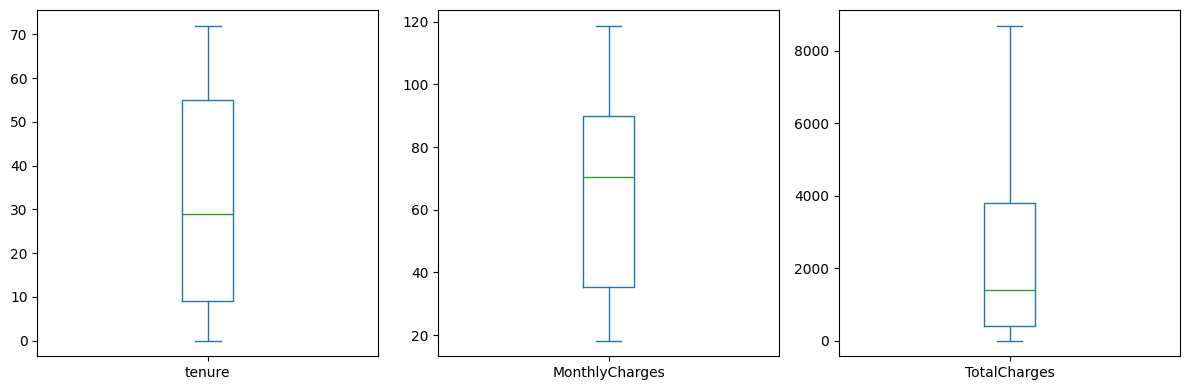

In [6]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[(df[col] < Q1 - 1.5 * IQR) |
                  (df[col] > Q3 + 1.5 * IQR)]

    print(col, "- Outliers:", len(outliers))

# Visualize outliers
df[num_cols].plot(kind='box', subplots=True, layout=(1, 3),
                  figsize=(12, 4))

plt.tight_layout()
plt.show()

# Retain outliers because they may be valid customer records

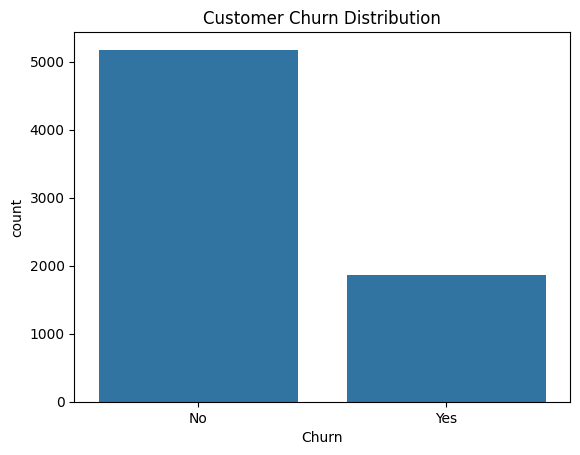

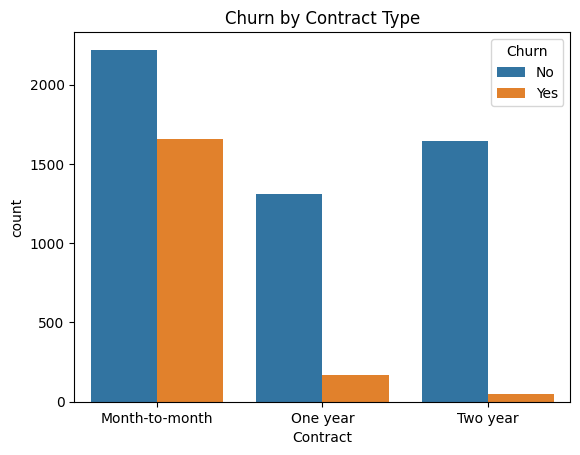

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [7]:
# Create a new feature
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['New', 'Medium', 'Long', 'Very Long']
)

# Churn distribution
sns.countplot(data=df, x='Churn')
plt.title("Customer Churn Distribution")
plt.show()

# Churn by contract type
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title("Churn by Contract Type")
plt.show()

print("Churn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

In [8]:
# Separate features and target
X = df.drop(['customerID', 'Churn'], axis=1)
y = df['Churn'].map({'No': 0, 'Yes': 1})

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numerical columns
scaler = StandardScaler()

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 33)
Testing data: (1409, 33)


In [9]:
df.to_csv("Cleaned_Telecom_Customer_Churn.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
